In [1]:
import os, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

model = joblib.load("../models/xgb2.joblib")
feature_cols = joblib.load("../models/feature_columns.joblib")
test_f = pd.read_parquet("../data/test_predictions.parquet")

X_test2 = pd.get_dummies(test_f, columns=['StoreType', 'Assortment'], dtype=int)
X_test2 = X_test2.reindex(columns=feature_cols, fill_value=0)
print(X_test2.shape)   # expect (40282, 25)

(40282, 25)


In [2]:
import xgboost as xgb

sample = X_test2.sample(2000, random_state=42)
contribs = model.get_booster().predict(xgb.DMatrix(sample), pred_contribs=True)
shap_values = contribs[:, :-1]   # last column is the bias term
print(shap_values.shape)

(2000, 25)


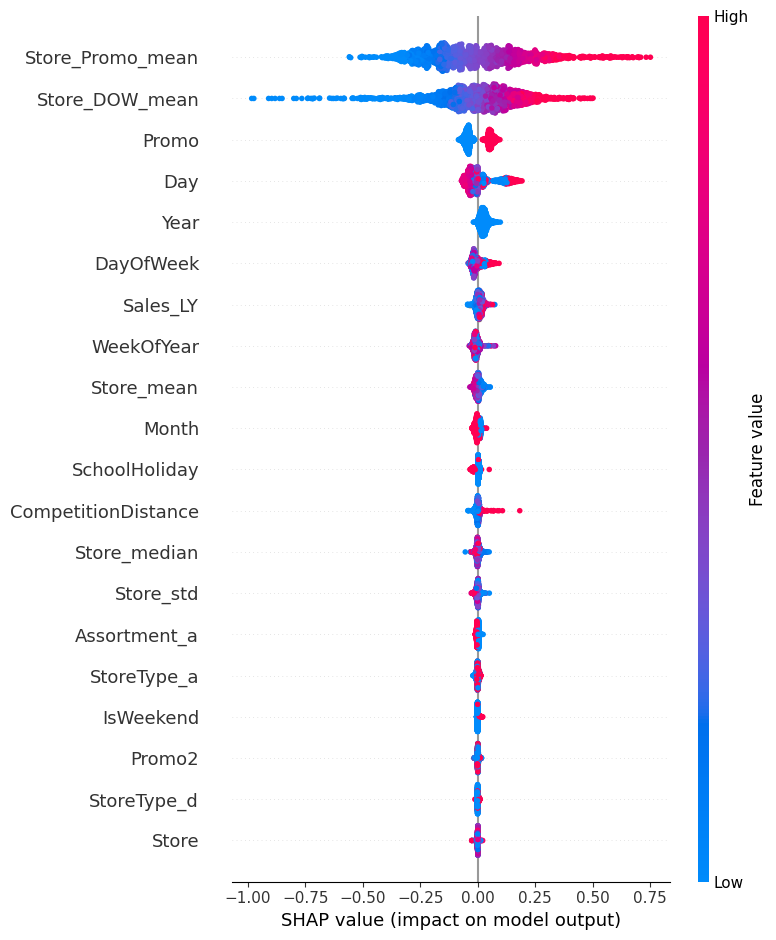

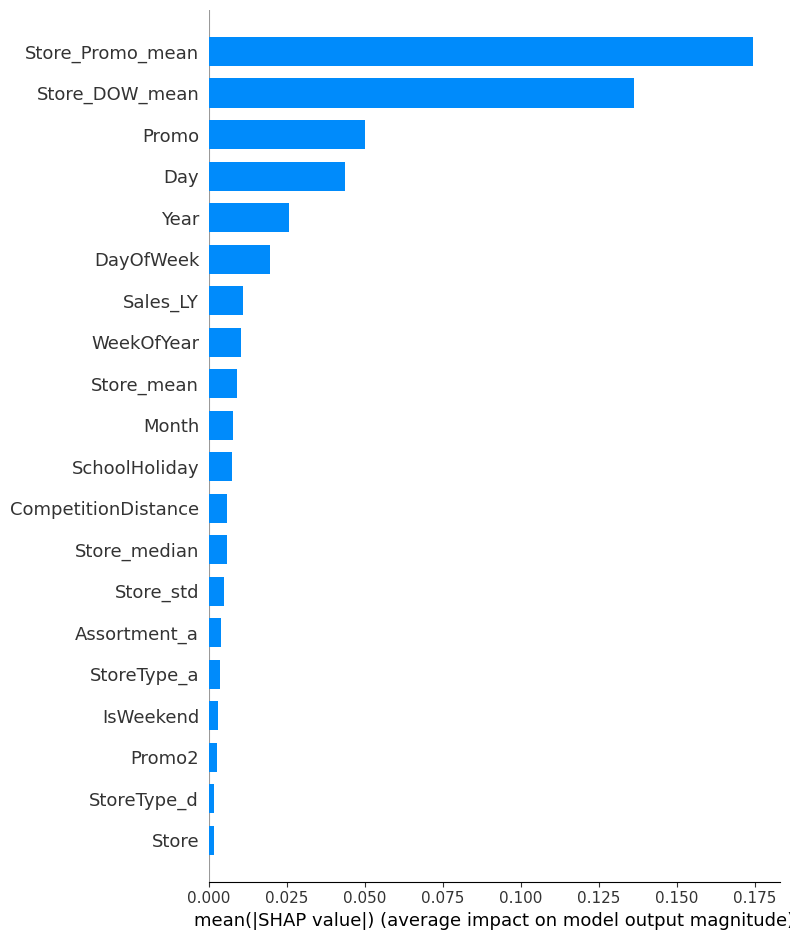

In [3]:
os.makedirs("../reports/figures", exist_ok=True)

shap.summary_plot(shap_values, sample, show=False)
plt.savefig("../reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

shap.summary_plot(shap_values, sample, plot_type="bar", show=False)
plt.savefig("../reports/figures/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

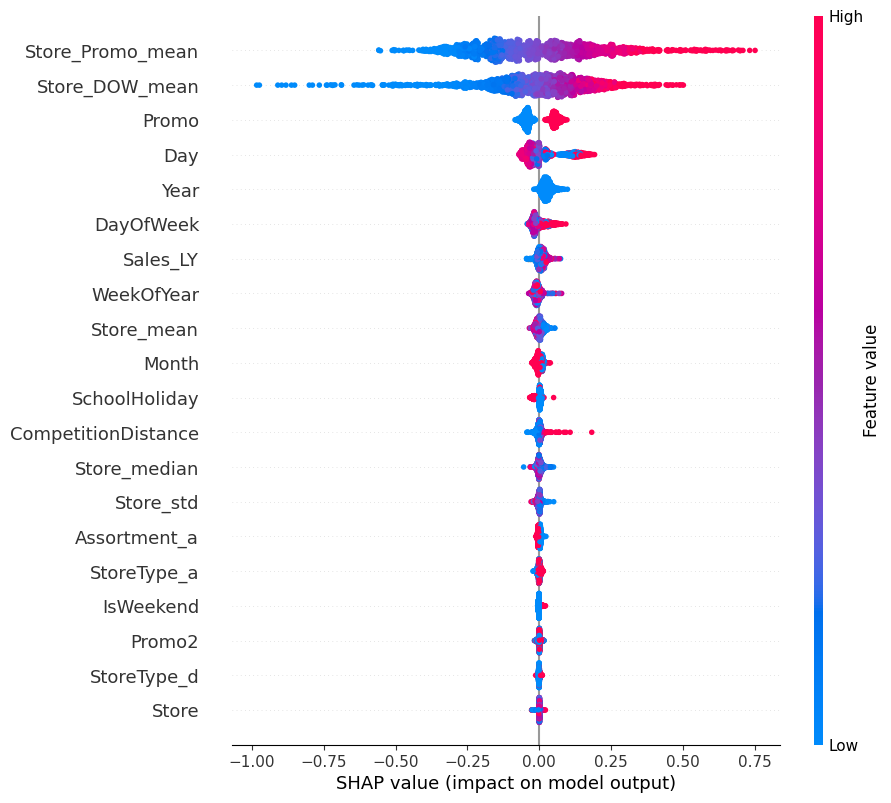

In [4]:
shap.summary_plot(shap_values, sample, show=False, max_display=20)
plt.gcf().set_size_inches(10, 8)
plt.savefig("../reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()